<a href="https://colab.research.google.com/github/aleakucing/Pembelajaran-Memsin/blob/main/JS08_Assigment01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
import scipy.cluster.hierarchy as sch

sns.set_theme(style="whitegrid")

In [14]:
df = pd.read_csv('/content/drive/MyDrive/PemMes/JS7/CC_Customer_Dataset.csv')

df.info()

df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [15]:
df.columns = df.columns.str.strip()

drop_cols = [col for col in ['Sl_No', 'Customer Key', 'Customer_Key', 'Unnamed: 0'] if col in df.columns]
X = df.drop(columns=drop_cols)

print("Fitur yang digunakan:")
print(X.columns.tolist())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Fitur yang digunakan:
['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


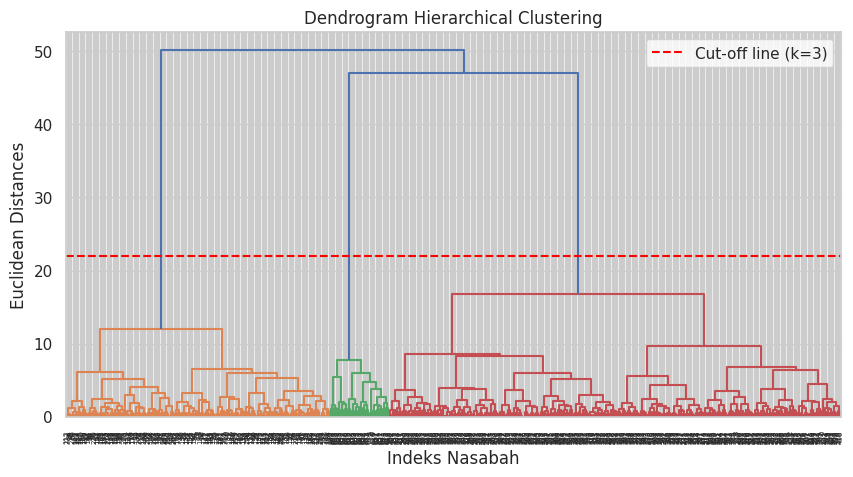

In [16]:
plt.figure(figsize=(10, 5))
dendrogram = sch.dendrogram(sch.linkage(X_scaled, method='ward'))

plt.title('Dendrogram Hierarchical Clustering')
plt.xlabel('Indeks Nasabah')
plt.ylabel('Euclidean Distances')
plt.axhline(y=22, color='red', linestyle='--', label='Cut-off line (k=3)')
plt.legend()
plt.show()

In [17]:
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
df['Cluster'] = hc.fit_predict(X_scaled)

print(df['Cluster'].value_counts())

Cluster
0    385
1    225
2     50
Name: count, dtype: int64


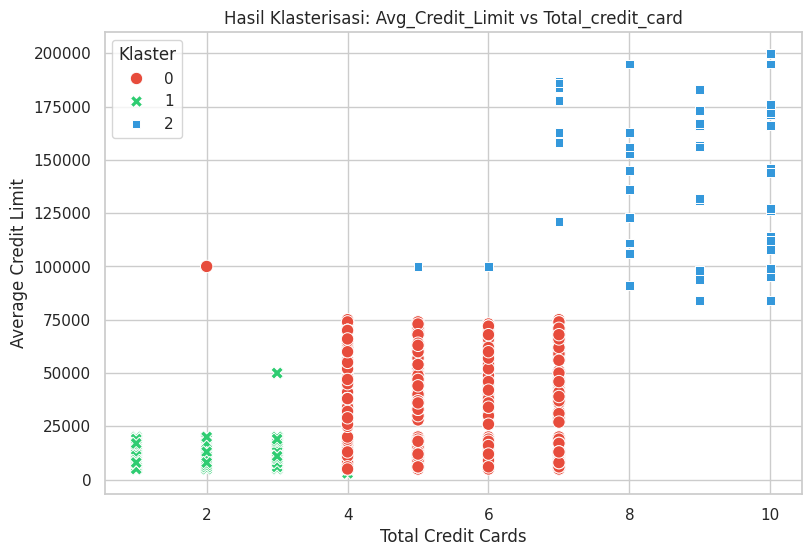

In [18]:
target_cc = 'Total_credit_card' if 'Total_credit_card' in df.columns else 'Total_Credit_Cards'

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x=target_cc,
    y='Avg_Credit_Limit',
    hue='Cluster',
    palette=['#e74c3c', '#2ecc71', '#3498db'],
    style='Cluster',
    s=80
)

plt.title('Hasil Klasterisasi: Avg_Credit_Limit vs Total_credit_card')
plt.xlabel('Total Credit Cards')
plt.ylabel('Average Credit Limit')
plt.legend(title='Klaster')
plt.show()

In [19]:
sil = silhouette_score(X_scaled, df['Cluster'])
dbi = davies_bouldin_score(X_scaled, df['Cluster'])

print(f"Silhouette Score    : {sil:.4f}")
print(f"Davies-Bouldin Index: {dbi:.4f}")

Silhouette Score    : 0.5148
Davies-Bouldin Index: 0.6810
